In [6]:
import os

# ╔══════════════════════════════════════════════════════╗
# ║           PROJECT PATHS — edit only here             ║
# ╚══════════════════════════════════════════════════════╝
BASE_DIR     = os.path.expanduser('~/Documents/FORESTesprit/USA_segmentation')

IMAGE_DIR    = os.path.join(BASE_DIR, 'RGB_images')
MASK_DIR     = os.path.join(BASE_DIR, 'masks')
MODEL_DIR    = os.path.join(BASE_DIR, 'models')
UNET_DIR     = os.path.join(BASE_DIR, 'unet_predicted_masks')
RCNN_DIR     = os.path.join(BASE_DIR, 'maskrcnn_predicted_masks')
BAD_TREE_DIR = os.path.join(BASE_DIR, 'bad_tree_masks')
ANNOT_DIR    = os.path.join(BASE_DIR, 'annotated_bad_tree_masks')
CONTOUR_DIR  = os.path.join(BASE_DIR, 'annotated_with_contours')
VIZ_DIR      = os.path.join(BASE_DIR, 'visualizations')

# Create output directories
for d in [MODEL_DIR, UNET_DIR, RCNN_DIR, BAD_TREE_DIR,
           ANNOT_DIR, CONTOUR_DIR, VIZ_DIR]:
    os.makedirs(d, exist_ok=True)

print('✅ Paths configured:')
print(f'   Images  : {IMAGE_DIR}')
print(f'   Masks   : {MASK_DIR}')
print(f'   Models  : {MODEL_DIR}')


✅ Paths configured:
   Images  : C:\Users\HUAWEI/Documents/FORESTesprit/USA_segmentation\RGB_images
   Masks   : C:\Users\HUAWEI/Documents/FORESTesprit/USA_segmentation\masks
   Models  : C:\Users\HUAWEI/Documents/FORESTesprit/USA_segmentation\models


In [7]:
!pip install tensorflow

import os
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from sklearn.model_selection import train_test_split
from tqdm import tqdm

IMG_HEIGHT   = 224
IMG_WIDTH    = 224
IMG_CHANNELS = 3


def load_dataset(image_dir, mask_dir, img_height, img_width):
    images, masks = [], []
    image_files = sorted([f for f in os.listdir(image_dir) if f.endswith('.png')])

    for filename in tqdm(image_files, desc='Loading images and masks'):
        try:
            img = load_img(os.path.join(image_dir, filename),
                           target_size=(img_height, img_width))
            img = img_to_array(img) / 255.0
            images.append(img)

            mask_name = filename.replace('RGB_', 'mask_')
            mask = load_img(os.path.join(mask_dir, mask_name),
                            color_mode='grayscale',
                            target_size=(img_height, img_width))
            mask = np.round(img_to_array(mask) / 255.0)
            masks.append(mask)
        except Exception as e:
            print(f'Skipping {filename}: {e}')

    return np.array(images), np.array(masks)


X, Y = load_dataset(IMAGE_DIR, MASK_DIR, IMG_HEIGHT, IMG_WIDTH)
print(f'Loaded {X.shape[0]} images — shape {X.shape[1:]}')


Loading images and masks: 100%|██████████| 444/444 [00:20<00:00, 21.76it/s]


Loaded 444 images — shape (224, 224, 3)


In [8]:
from sklearn.model_selection import train_test_split

X_train, X_temp, Y_train, Y_temp = train_test_split(X, Y, test_size=0.3, random_state=42)
X_val,   X_test, Y_val,   Y_test = train_test_split(X_temp, Y_temp, test_size=0.5, random_state=42)

print(f'Train : {X_train.shape[0]} samples')
print(f'Val   : {X_val.shape[0]} samples')
print(f'Test  : {X_test.shape[0]} samples')


Train : 310 samples
Val   : 67 samples
Test  : 67 samples


## Data Augmentation with Albumentations

In [10]:
!pip install albumentations -q


In [11]:
import albumentations as A
import random

augmentation = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomBrightnessContrast(p=0.5),
    A.Rotate(limit=30, p=0.5),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.05, rotate_limit=0, p=0.5),
    A.RandomCrop(height=224, width=224, p=1.0),
])

def augment_image_mask(image, mask):
    aug = augmentation(image=image, mask=mask)
    return aug['image'], aug['mask']


C:\Users\HUAWEI\anaconda3\Lib\site-packages\albumentations\core\validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


### Test augmentation on a sample

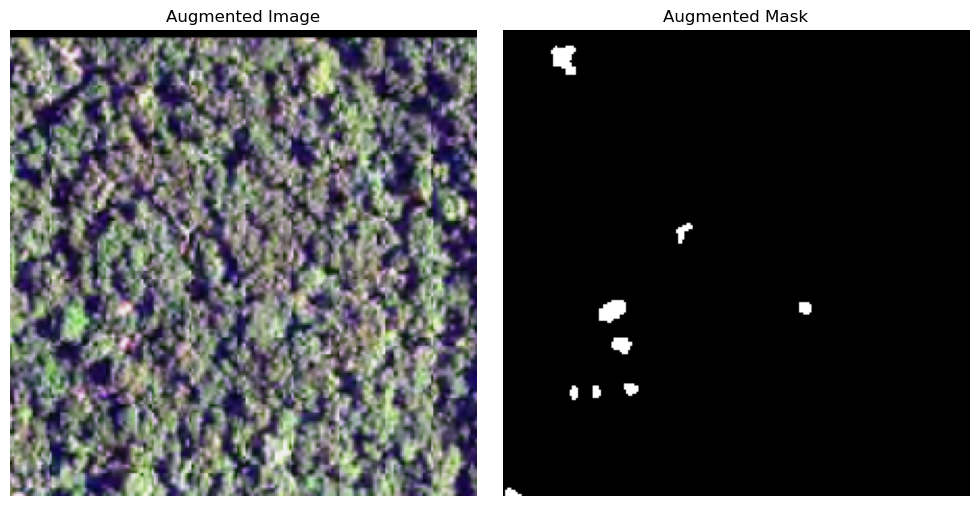

In [13]:
import matplotlib.pyplot as plt

idx = random.randint(0, len(X_train) - 1)
aug_img, aug_mask = augment_image_mask(
    (X_train[idx] * 255).astype(np.uint8),
    (Y_train[idx] * 255).astype(np.uint8)
)

fig, axs = plt.subplots(1, 2, figsize=(10, 5))
axs[0].imshow(aug_img / 255.0);  axs[0].set_title('Augmented Image');  axs[0].axis('off')
axs[1].imshow(aug_mask.squeeze() / 255.0, cmap='gray');  axs[1].set_title('Augmented Mask');  axs[1].axis('off')
plt.tight_layout(); plt.show()


In [14]:
from tensorflow.keras import layers, models

def build_unet(input_shape=(224, 224, 3)):
    inputs = layers.Input(shape=input_shape)

    # Encoder
    c1 = layers.Conv2D(64,   3, activation='relu', padding='same')(inputs)
    c1 = layers.Conv2D(64,   3, activation='relu', padding='same')(c1)
    p1 = layers.MaxPooling2D(2)(c1)

    c2 = layers.Conv2D(128,  3, activation='relu', padding='same')(p1)
    c2 = layers.Conv2D(128,  3, activation='relu', padding='same')(c2)
    p2 = layers.MaxPooling2D(2)(c2)

    c3 = layers.Conv2D(256,  3, activation='relu', padding='same')(p2)
    c3 = layers.Conv2D(256,  3, activation='relu', padding='same')(c3)
    p3 = layers.MaxPooling2D(2)(c3)

    c4 = layers.Conv2D(512,  3, activation='relu', padding='same')(p3)
    c4 = layers.Conv2D(512,  3, activation='relu', padding='same')(c4)
    p4 = layers.MaxPooling2D(2)(c4)

    # Bottleneck
    c5 = layers.Conv2D(1024, 3, activation='relu', padding='same')(p4)
    c5 = layers.Conv2D(1024, 3, activation='relu', padding='same')(c5)

    # Decoder
    u6 = layers.Conv2DTranspose(512, 2, strides=2, padding='same')(c5)
    u6 = layers.concatenate([u6, c4])
    c6 = layers.Conv2D(512,  3, activation='relu', padding='same')(u6)
    c6 = layers.Conv2D(512,  3, activation='relu', padding='same')(c6)

    u7 = layers.Conv2DTranspose(256, 2, strides=2, padding='same')(c6)
    u7 = layers.concatenate([u7, c3])
    c7 = layers.Conv2D(256,  3, activation='relu', padding='same')(u7)
    c7 = layers.Conv2D(256,  3, activation='relu', padding='same')(c7)

    u8 = layers.Conv2DTranspose(128, 2, strides=2, padding='same')(c7)
    u8 = layers.concatenate([u8, c2])
    c8 = layers.Conv2D(128,  3, activation='relu', padding='same')(u8)
    c8 = layers.Conv2D(128,  3, activation='relu', padding='same')(c8)

    u9 = layers.Conv2DTranspose(64,  2, strides=2, padding='same')(c8)
    u9 = layers.concatenate([u9, c1])
    c9 = layers.Conv2D(64,   3, activation='relu', padding='same')(u9)
    c9 = layers.Conv2D(64,   3, activation='relu', padding='same')(c9)

    outputs = layers.Conv2D(1, 1, activation='sigmoid')(c9)
    return models.Model(inputs=[inputs], outputs=[outputs])


In [15]:
import tensorflow.keras.backend as K

def dice_coefficient(y_true, y_pred, smooth=1):
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (K.sum(y_true_f) + K.sum(y_pred_f) + smooth)

def dice_loss(y_true, y_pred):
    return 1 - dice_coefficient(y_true, y_pred)


In [16]:
unet_model = build_unet()
unet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=dice_loss,
    metrics=[dice_coefficient, tf.keras.metrics.BinaryAccuracy()]
)
unet_model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 224, 224,  │      1,792 │ input_layer[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 224, 224,  │     36,928 │ conv2d[0][0]      │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 112, 112,  │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 112, 112,  │     73,856 │ max_pooling2d[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 112, 112,  │    147,584 │ conv2d_2[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 56, 56,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 56, 56,    │    295,168 │ max_pooling2d_1[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 56, 56,    │    590,080 │ conv2d_4[0][0]    │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 28, 28,    │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 28, 28,    │  1,180,160 │ max_pooling2d_2[… │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 28, 28,    │  2,359,808 │ conv2d_6[0][0]    │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 14, 14,    │          0 │ conv2d_7[0][0]    │
│ (MaxPooling2D)      │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 14, 14,    │  4,719,616 │ max_pooling2d_3[… │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 14, 14,    │  9,438,208 │ conv2d_8[0][0]    │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (None, 28, 28,    │  2,097,664 │ conv2d_9[0][0]    │
│ (Conv2DTranspose)   │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 28, 28,    │          0 │ conv2d_transpose

 Total params: 31,031,745 (118.38 MB)

 Trainable params: 31,031,745 (118.38 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
print('X_train:', X_train.shape, ' Y_train:', Y_train.shape)
print('X_val  :', X_val.shape,   ' Y_val  :', Y_val.shape)


X_train: (310, 224, 224, 3)  Y_train: (310, 224, 224, 1)
X_val  : (67, 224, 224, 3)  Y_val  : (67, 224, 224, 1)


In [ ]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

MODEL_SAVE_PATH = os.path.join(MODEL_DIR, 'best_unet_model.h5')

checkpoint = ModelCheckpoint(
    MODEL_SAVE_PATH,
    monitor='val_loss', mode='min',
    save_best_only=True, verbose=1
)
early_stop = EarlyStopping(
    monitor='val_loss', patience=10,
    restore_best_weights=True, verbose=1
)

history = unet_model.fit(
    X_train, Y_train,
    validation_data=(X_val, Y_val),
    batch_size=8,   # reduce to 4 if you run out of memory
    epochs=100,
    callbacks=[checkpoint, early_stop]
)


Epoch 1/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 8s/step - binary_accuracy: 0.0219 - dice_coefficient: 0.0386 - loss: 0.9614
Epoch 1: val_loss improved from None to 0.96086, saving model to C:\Users\HUAWEI/Documents/FORESTesprit/USA_segmentation\models\best_unet_model.h5



Epoch 1: finished saving model to C:\Users\HUAWEI/Documents/FORESTesprit/USA_segmentation\models\best_unet_model.h5
39/39 ━━━━━━━━━━━━━━━━━━━━ 336s 8s/step - binary_accuracy: 0.0224 - dice_coefficient: 0.0383 - loss: 0.9618 - val_binary_accuracy: 0.0765 - val_dice_coefficient: 0.0387 - val_loss: 0.9609
Epoch 2/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 75s/step - binary_accuracy: 0.5625 - dice_coefficient: 0.0578 - loss: 0.9422  
Epoch 2: val_loss improved from 0.96086 to 0.81239, saving model to C:\Users\HUAWEI/Documents/FORESTesprit/USA_segmentation\models\best_unet_model.h5



Epoch 2: finished saving model to C:\Users\HUAWEI/Documents/FORESTesprit/USA_segmentation\models\best_unet_model.h5
39/39 ━━━━━━━━━━━━━━━━━━━━ 2904s 76s/step - binary_accuracy: 0.7104 - dice_coefficient: 0.0782 - loss: 0.9224 - val_binary_accuracy: 0.9634 - val_dice_coefficient: 0.1871 - val_loss: 0.8124
Epoch 3/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 31s/step - binary_accuracy: 0.9579 - dice_coefficient: 0.2248 - loss: 0.7752 
Epoch 3: val_loss improved from 0.81239 to 0.64241, saving model to C:\Users\HUAWEI/Documents/FORESTesprit/USA_segmentation\models\best_unet_model.h5



Epoch 3: finished saving model to C:\Users\HUAWEI/Documents/FORESTesprit/USA_segmentation\models\best_unet_model.h5
39/39 ━━━━━━━━━━━━━━━━━━━━ 1205s 31s/step - binary_accuracy: 0.9684 - dice_coefficient: 0.2815 - loss: 0.7186 - val_binary_accuracy: 0.9784 - val_dice_coefficient: 0.3574 - val_loss: 0.6424
Epoch 4/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 10s/step - binary_accuracy: 0.9757 - dice_coefficient: 0.3553 - loss: 0.6448 
Epoch 4: val_loss did not improve from 0.64241
39/39 ━━━━━━━━━━━━━━━━━━━━ 431s 11s/step - binary_accuracy: 0.9761 - dice_coefficient: 0.3791 - loss: 0.6218 - val_binary_accuracy: 0.9836 - val_dice_coefficient: 0.3573 - val_loss: 0.6471
Epoch 5/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 11s/step - binary_accuracy: 0.9774 - dice_coefficient: 0.4019 - loss: 0.5981 
Epoch 5: val_loss improved from 0.64241 to 0.58990, saving model to C:\Users\HUAWEI/Documents/FORESTesprit/USA_segmentation\models\best_unet_model.h5



Epoch 5: finished saving model to C:\Users\HUAWEI/Documents/FORESTesprit/USA_segmentation\models\best_unet_model.h5
39/39 ━━━━━━━━━━━━━━━━━━━━ 447s 11s/step - binary_accuracy: 0.9778 - dice_coefficient: 0.4093 - loss: 0.5909 - val_binary_accuracy: 0.9793 - val_dice_coefficient: 0.4097 - val_loss: 0.5899
Epoch 6/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 12s/step - binary_accuracy: 0.9785 - dice_coefficient: 0.4096 - loss: 0.5904 
Epoch 6: val_loss did not improve from 0.58990
39/39 ━━━━━━━━━━━━━━━━━━━━ 486s 12s/step - binary_accuracy: 0.9770 - dice_coefficient: 0.4159 - loss: 0.5834 - val_binary_accuracy: 0.9705 - val_dice_coefficient: 0.3766 - val_loss: 0.6217
Epoch 7/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 9s/step - binary_accuracy: 0.9807 - dice_coefficient: 0.4697 - loss: 0.5303
Epoch 8: val_loss did not improve from 0.56989
39/39 ━━━━━━━━━━━━━━━━━━━━ 369s 9s/step - binary_accuracy: 0.9787 - dice_coefficient: 0.4423 - loss: 0.5574 - val_binary_accuracy: 0.9814 - val_dice_coefficient: 0.4316 - va


Epoch 10: finished saving model to C:\Users\HUAWEI/Documents/FORESTesprit/USA_segmentation\models\best_unet_model.h5
39/39 ━━━━━━━━━━━━━━━━━━━━ 352s 9s/step - binary_accuracy: 0.9793 - dice_coefficient: 0.4540 - loss: 0.5454 - val_binary_accuracy: 0.9831 - val_dice_coefficient: 0.4501 - val_loss: 0.5549
Epoch 11/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 9s/step - binary_accuracy: 0.9807 - dice_coefficient: 0.4746 - loss: 0.5254
Epoch 11: val_loss did not improve from 0.55485
39/39 ━━━━━━━━━━━━━━━━━━━━ 364s 9s/step - binary_accuracy: 0.9804 - dice_coefficient: 0.4754 - loss: 0.5248 - val_binary_accuracy: 0.9836 - val_dice_coefficient: 0.4453 - val_loss: 0.5598
Epoch 12/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 8s/step - binary_accuracy: 0.9813 - dice_coefficient: 0.4805 - loss: 0.5195
Epoch 12: val_loss did not improve from 0.55485
39/39 ━━━━━━━━━━━━━━━━━━━━ 352s 9s/step - binary_accuracy: 0.9810 - dice_coefficient: 0.4730 - loss: 0.5271 - val_binary_accuracy: 0.9665 - val_dice_coefficient: 0.3959 - v


Epoch 13: finished saving model to C:\Users\HUAWEI/Documents/FORESTesprit/USA_segmentation\models\best_unet_model.h5
39/39 ━━━━━━━━━━━━━━━━━━━━ 342s 9s/step - binary_accuracy: 0.9799 - dice_coefficient: 0.4769 - loss: 0.5236 - val_binary_accuracy: 0.9809 - val_dice_coefficient: 0.4618 - val_loss: 0.5421
Epoch 14/100
 4/39 ━━━━━━━━━━━━━━━━━━━━ 4:36 8s/step - binary_accuracy: 0.9732 - dice_coefficient: 0.4455 - loss: 0.5545

In [ ]:
# Run this cell only if you want to resume from saved weights
# (skip after training — best weights are already restored by EarlyStopping)
WEIGHTS_PATH = os.path.join(MODEL_DIR, 'best_unet_model.h5')
unet_model.load_weights(WEIGHTS_PATH)
print(f'✅ Weights loaded from {WEIGHTS_PATH}')


In [ ]:
import pickle

history_path = os.path.join(MODEL_DIR, 'history.pkl')
with open(history_path, 'wb') as f:
    pickle.dump(history.history, f)
print(f'✅ History saved to {history_path}')


In [ ]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 3, figsize=(15, 4))

axs[0].plot(history.history['loss'],               label='Train')
axs[0].plot(history.history['val_loss'],            label='Val')
axs[0].set_title('Loss'); axs[0].set_xlabel('Epoch'); axs[0].legend()

axs[1].plot(history.history['dice_coefficient'],    label='Train')
axs[1].plot(history.history['val_dice_coefficient'],label='Val')
axs[1].set_title('Dice Coefficient'); axs[1].set_xlabel('Epoch'); axs[1].legend()

axs[2].plot(history.history['binary_accuracy'],     label='Train')
axs[2].plot(history.history['val_binary_accuracy'], label='Val')
axs[2].set_title('Binary Accuracy'); axs[2].set_xlabel('Epoch'); axs[2].legend()

plt.tight_layout(); plt.show()


In [ ]:
MODEL_SAVE_PATH = os.path.join(MODEL_DIR, 'best_unet_model.h5')
unet_model.save(MODEL_SAVE_PATH)
print(f'✅ Model saved to {MODEL_SAVE_PATH}')


In [ ]:
from tensorflow.keras.models import load_model

MODEL_SAVE_PATH = os.path.join(MODEL_DIR, 'best_unet_model.h5')
best_model = load_model(
    MODEL_SAVE_PATH,
    custom_objects={'dice_coefficient': dice_coefficient, 'dice_loss': dice_loss}
)
print('✅ Model loaded successfully.')


In [ ]:
test_results = best_model.evaluate(X_test, Y_test, verbose=1)
print(f'Test Loss            : {test_results[0]:.4f}')
print(f'Test Dice Coefficient: {test_results[1]:.4f}')
print(f'Test Binary Accuracy : {test_results[2]:.4f}')


In [ ]:
best_model.compile(
    optimizer='adam',
    loss=dice_loss,
    metrics=[dice_coefficient, 'binary_accuracy']
)

Y_pred     = best_model.predict(X_val)
Y_pred_bin = (Y_pred > 0.5).astype(np.uint8)
Y_val_bin  = (Y_val  > 0.5).astype(np.uint8)


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score, jaccard_score

y_true = Y_val_bin.flatten()
y_pred = Y_pred_bin.flatten()

print(f'Precision      : {precision_score(y_true, y_pred):.4f}')
print(f'Recall         : {recall_score(y_true, y_pred):.4f}')
print(f'F1 Score (Dice): {f1_score(y_true, y_pred):.4f}')
print(f'IoU (Jaccard)  : {jaccard_score(y_true, y_pred):.4f}')


✅ Good Score Benchmarks (binary segmentation):
| Metric               | Good Value                                        |
| -------------------- | ------------------------------------------------- |
| **Dice / F1**        | > 0.85 (excellent), > 0.75 (good)                 |
| **IoU**              | > 0.7 (good), > 0.8 (very good)                   |
| **Accuracy**         | > 0.9, but less useful alone                      |
| **Precision/Recall** | depends on imbalance — balanced scores are better |
=>Sure! Here's a brief conclusion:

---

The model shows moderate performance with about 60% F1 score and recall, indicating it detects a fair number of true positives but also misses some. Precision near 59% suggests some false positives occur. The IoU of 43% reflects moderate overlap between predicted and actual regions, showing room for improvement in segmentation accuracy. Overall, the results are promising but further tuning and data enhancement are needed to boost performance.




In [ ]:
def display_predictions(X, Y_true, Y_pred, index=0):
    fig, axs = plt.subplots(1, 3, figsize=(12, 4))
    axs[0].imshow(X[index]);                         axs[0].set_title('Input Image');   axs[0].axis('off')
    axs[1].imshow(Y_true[index].squeeze(), cmap='gray'); axs[1].set_title('Ground Truth'); axs[1].axis('off')
    axs[2].imshow(Y_pred[index].squeeze(), cmap='gray'); axs[2].set_title('Prediction');   axs[2].axis('off')
    plt.tight_layout(); plt.show()

for i in range(3):
    display_predictions(X_val, Y_val, Y_pred_bin, index=i)


In [ ]:
import cv2

for i in range(len(Y_pred_bin)):
    mask = (Y_pred_bin[i].squeeze() * 255).astype(np.uint8)
    cv2.imwrite(os.path.join(UNET_DIR, f'unet_mask_{i+1}.png'), mask)

print(f'✅ Saved {len(Y_pred_bin)} U-Net masks to {UNET_DIR}')


## Counting Bad Trees

In [ ]:
for i in range(len(Y_pred_bin)):
    mask = (Y_pred_bin[i].squeeze() * 255).astype(np.uint8)
    cv2.imwrite(os.path.join(BAD_TREE_DIR, f'mask_{i+1}.png'), mask)

print(f'✅ Saved {len(Y_pred_bin)} bad-tree masks to {BAD_TREE_DIR}')


In [ ]:
total_trees     = 0
per_image_counts = {}

for filename in sorted(os.listdir(BAD_TREE_DIR)):
    if not filename.endswith(('.png', '.jpg')):
        continue
    mask = cv2.imread(os.path.join(BAD_TREE_DIR, filename), cv2.IMREAD_GRAYSCALE)
    _, binary = cv2.threshold(mask, 127, 255, cv2.THRESH_BINARY)
    num_labels, _ = cv2.connectedComponents(binary)
    tree_count = num_labels - 1
    per_image_counts[filename] = tree_count
    total_trees += tree_count

for name, count in per_image_counts.items():
    print(f'{name}: {count} bad trees')
print(f'\n Total bad trees in dataset: {total_trees}')


In [ ]:
import csv

csv_path = os.path.join(BASE_DIR, 'bad_tree_counts.csv')
with open(csv_path, 'w', newline='') as f:
    w = csv.writer(f)
    w.writerow(['Image', 'Bad_Tree_Count'])
    for name, count in per_image_counts.items():
        w.writerow([name, count])
    w.writerow(['TOTAL', total_trees])
print(f'✅ Counts saved to {csv_path}')


## Visualise Masks with Tree Count

In [ ]:
font = cv2.FONT_HERSHEY_SIMPLEX

for filename in sorted(os.listdir(BAD_TREE_DIR)):
    if not filename.endswith(('.png', '.jpg')):
        continue
    mask = cv2.imread(os.path.join(BAD_TREE_DIR, filename), cv2.IMREAD_GRAYSCALE)
    _, binary = cv2.threshold(mask, 127, 255, cv2.THRESH_BINARY)
    num_labels, _ = cv2.connectedComponents(binary)
    tree_count = num_labels - 1
    mask_bgr = cv2.cvtColor(binary, cv2.COLOR_GRAY2BGR)
    cv2.putText(mask_bgr, f'Trees: {tree_count}', (10, 30),
                font, 1, (0, 0, 255), 2, cv2.LINE_AA)
    cv2.imwrite(os.path.join(ANNOT_DIR, f'annotated_{filename}'), mask_bgr)

# Show last result
plt.imshow(mask_bgr[..., ::-1])
plt.title(f'Bad Trees: {tree_count}'); plt.axis('off'); plt.show()
print(f'✅ Annotated masks saved to {ANNOT_DIR}')


In [ ]:
for filename in sorted(os.listdir(BAD_TREE_DIR)):
    if not filename.endswith(('.png', '.jpg')):
        continue
    mask = cv2.imread(os.path.join(BAD_TREE_DIR, filename), cv2.IMREAD_GRAYSCALE)
    _, binary = cv2.threshold(mask, 127, 255, cv2.THRESH_BINARY)
    contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    tree_count  = len(contours)
    annotated   = cv2.cvtColor(binary, cv2.COLOR_GRAY2BGR)
    cv2.drawContours(annotated, contours, -1, (0, 255, 0), 2)
    cv2.putText(annotated, f'Trees: {tree_count}', (10, 30),
                font, 1, (0, 0, 255), 2, cv2.LINE_AA)
    cv2.imwrite(os.path.join(CONTOUR_DIR, f'contour_{filename}'), annotated)

# Show last result
plt.imshow(annotated[..., ::-1])
plt.title(f'Detected Trees: {tree_count}'); plt.axis('off'); plt.show()
print(f'✅ Contour masks saved to {CONTOUR_DIR}')


## Mask R-CNN Setup

In [ ]:
!pip install torch torchvision -q


In [ ]:
import torch
import cv2
from PIL import Image
from torchvision import transforms
from torchvision.models.detection import (
    maskrcnn_resnet50_fpn, MaskRCNN_ResNet50_FPN_Weights
)


In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

rcnn_model = maskrcnn_resnet50_fpn(
    weights=MaskRCNN_ResNet50_FPN_Weights.DEFAULT
)
rcnn_model.eval().to(device)
print('✅ Mask R-CNN loaded.')


In [ ]:
transform = transforms.ToTensor()

for filename in sorted(os.listdir(MASK_DIR)):
    if not filename.endswith(('.png', '.jpg', '.jpeg')):
        continue
    image      = Image.open(os.path.join(MASK_DIR, filename)).convert('RGB')
    img_tensor = transform(image).to(device)

    with torch.no_grad():
        pred = rcnn_model([img_tensor])

    for i, score in enumerate(pred[0]['scores']):
        if score > 0.5:
            mask        = pred[0]['masks'][i, 0].detach().cpu().numpy()
            binary_mask = (mask > 0.5).astype(np.uint8) * 255
            save_name   = f"{os.path.splitext(filename)[0]}_mask_{i}.png"
            cv2.imwrite(os.path.join(RCNN_DIR, save_name), binary_mask)

print(f'✅ Mask R-CNN predictions saved to {RCNN_DIR}')


## U-Net vs Mask R-CNN Comparison

In [ ]:
def dice_coef(y_true, y_pred, smooth=1e-6):
    y_true, y_pred = y_true.flatten(), y_pred.flatten()
    intersection = np.sum(y_true * y_pred)
    return (2. * intersection + smooth) / (np.sum(y_true) + np.sum(y_pred) + smooth)

def iou_score(y_true, y_pred, smooth=1e-6):
    y_true, y_pred = y_true.flatten(), y_pred.flatten()
    intersection = np.sum(y_true * y_pred)
    union = np.sum(y_true) + np.sum(y_pred) - intersection
    return (intersection + smooth) / (union + smooth)


In [ ]:
print('GT Masks        :', len(os.listdir(MASK_DIR)))
print('U-Net Predictions:', len(os.listdir(UNET_DIR)))
print('Mask R-CNN Preds :', len(os.listdir(RCNN_DIR)))
print('GT sample  :', sorted(os.listdir(MASK_DIR))[:3])
print('UNet sample:', sorted(os.listdir(UNET_DIR))[:3])
print('RCNN sample:', sorted(os.listdir(RCNN_DIR))[:3])


In [ ]:
import pandas as pd
from sklearn.metrics import jaccard_score

gt_files      = sorted(os.listdir(MASK_DIR))
unet_files    = sorted(os.listdir(UNET_DIR))
maskrcnn_files = sorted(os.listdir(RCNN_DIR))

# Build Mask R-CNN file map: base.png -> first mask file
maskrcnn_dict = {}
for f in maskrcnn_files:
    if '_mask_' in f:
        base = f.split('_mask_')[0] + '.png'
        if base not in maskrcnn_dict:
            maskrcnn_dict[base] = f

common_files = sorted(set(gt_files) & set(unet_files) & set(maskrcnn_dict.keys()))
print(f'✅ {len(common_files)} common files found')

results = []

for fname in common_files:
    gt       = cv2.imread(os.path.join(MASK_DIR, fname), 0)
    unet     = cv2.imread(os.path.join(UNET_DIR, fname), 0)
    maskrcnn = cv2.imread(os.path.join(RCNN_DIR, maskrcnn_dict[fname]), 0)

    if unet.shape     != gt.shape: unet     = cv2.resize(unet,     (gt.shape[1], gt.shape[0]))
    if maskrcnn.shape != gt.shape: maskrcnn = cv2.resize(maskrcnn, (gt.shape[1], gt.shape[0]))

    gt_bin  = (gt       > 127).astype(np.uint8).flatten()
    un_bin  = (unet     > 127).astype(np.uint8).flatten()
    rc_bin  = (maskrcnn > 127).astype(np.uint8).flatten()

    results.append({
        'filename'        : fname,
        'U-Net Dice'      : 2*np.sum(gt_bin*un_bin)/(np.sum(gt_bin)+np.sum(un_bin)+1e-6),
        'U-Net IoU'       : jaccard_score(gt_bin, un_bin),
        'Mask R-CNN Dice' : 2*np.sum(gt_bin*rc_bin)/(np.sum(gt_bin)+np.sum(rc_bin)+1e-6),
        'Mask R-CNN IoU'  : jaccard_score(gt_bin, rc_bin),
    })

df = pd.DataFrame(results)
print(df.head())
print('\n✅ Global Averages:')
print(df.mean(numeric_only=True))


In [ ]:
%matplotlib inline

def overlay_mask(image, mask, color=(0, 255, 0), alpha=0.5):
    out = image.copy()
    colored = np.zeros_like(image)
    colored[mask > 127] = color
    return cv2.addWeighted(out, 1 - alpha, colored, alpha, 0)


for idx, fname in enumerate(common_files[:5]):
    base_name  = fname.replace('mask_', '').replace('.png', '')
    rgb_name   = f'RGB_{base_name}.png'
    image_path = os.path.join(IMAGE_DIR, rgb_name)

    if not os.path.exists(image_path):
        print(f'⚠️  RGB image not found: {rgb_name}')
        continue

    gt       = cv2.imread(os.path.join(MASK_DIR, fname), 0)
    unet     = cv2.imread(os.path.join(UNET_DIR, fname), 0)
    maskrcnn = cv2.imread(os.path.join(RCNN_DIR, maskrcnn_dict[fname]), 0)
    rgb      = cv2.cvtColor(cv2.imread(image_path), cv2.COLOR_BGR2RGB)

    gt       = cv2.resize(gt,       (rgb.shape[1], rgb.shape[0]))
    unet     = cv2.resize(unet,     (rgb.shape[1], rgb.shape[0]))
    maskrcnn = cv2.resize(maskrcnn, (rgb.shape[1], rgb.shape[0]))

    row = next(r for r in results if r['filename'] == fname)

    fig, axs = plt.subplots(2, 3, figsize=(18, 10))
    axs[0,0].imshow(rgb);                         axs[0,0].set_title('Original Image')
    axs[0,1].imshow(gt,       cmap='gray');       axs[0,1].set_title('Ground Truth')
    axs[0,2].imshow(unet,     cmap='gray');       axs[0,2].set_title(f"U-Net  Dice={row['U-Net Dice']:.3f}  IoU={row['U-Net IoU']:.3f}")
    axs[1,0].imshow(overlay_mask(rgb, gt,       (255,0,0)));  axs[1,0].set_title('GT Overlay (Red)')
    axs[1,1].imshow(overlay_mask(rgb, unet,     (0,255,0)));  axs[1,1].set_title('U-Net Overlay (Green)')
    axs[1,2].imshow(overlay_mask(rgb, maskrcnn, (0,0,255)));  axs[1,2].set_title(f"Mask R-CNN Overlay (Blue)  Dice={row['Mask R-CNN Dice']:.3f}")
    for ax in axs.flat: ax.axis('off')
    plt.suptitle(base_name, fontsize=14)
    plt.tight_layout()
    save_path = os.path.join(VIZ_DIR, base_name + '_comparison.png')
    plt.savefig(save_path, dpi=150)
    plt.show()
    print(f'✅ Saved {save_path}')


In [ ]:
csv_out = os.path.join(BASE_DIR, 'results_comparison.csv')
df.to_csv(csv_out, index=False)
print(f'✅ Metrics exported to {csv_out}')


In [ ]:
for folder in [UNET_DIR, RCNN_DIR, BAD_TREE_DIR, ANNOT_DIR, VIZ_DIR]:
    n = len(os.listdir(folder)) if os.path.exists(folder) else 0
    print(f'{n:4d} files  →  {folder}')
